<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# APIs Marketing Strategy - Solution

---

### About
Understand how to use an API to gather data.

### Learning Objectives
- Get data from the web using API requests

### Notebook Guide
1. Getting Police Data
2. Now You Try

In [1]:
import pandas as pd

---
# Getting Police Data

Let's request data from this API: https://data.police.uk/docs/

Take a few moments to read through some of the information on this site and figure out:

* Where this API gets its data from (and whether it's a reputable source)
* How we can access the documentation that tells us how the API works
* Whether the API is free

<details><summary>Which endpoint looks promising to help us answer our challenge of finding out about the prevalence of different types of crimes around the UK?</summary>

The ‘street level crimes’ endpoint looks promising: https://data.police.uk/docs/method/crime-street/
</details>

Let's start by importing the `requests` library, which we'll be using to make API requests.

In [2]:
import requests

Let's make a request to the police API and view the resulting JSON. The first thing we do is make a GET request. This is really simple!

In [3]:
crime_request = requests.get('https://data.police.uk/api/crimes-street/all-crime?date=2023-01&lat=52.629729&lng=-1.131592')#'https://data.police.uk/api/crimes-street/all-crime?lat=52.629729&lng=-1.131592&date=2023-01')
crime_request

<Response [404]>

The thing we get back from a GET request is a `request` object.

In [4]:
type(crime_request)

requests.models.Response

This is an object that has a few different bits of information bundled up inside it, all of which have been sent back to us by the servers.

The thing we're interested in, is accessing the JSON (or dictionary) data that's returned by the API. We do this in a single step:



In [5]:
crime_request.json()

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

Let's create a variable that contains the JSON only.

In [ ]:
crime_json = crime_request.json()
crime_json

[{'category': 'anti-social-behaviour',
  'location_type': 'Force',
  'location': {'latitude': '52.625551',
   'street': {'id': 1737260, 'name': 'On or near Petrol Station'},
   'longitude': '-1.152191'},
  'context': '',
  'outcome_status': None,
  'persistent_id': '',
  'id': 116208943,
  'location_subtype': '',
  'month': '2024-01'},
 {'category': 'anti-social-behaviour',
  'location_type': 'Force',
  'location': {'latitude': '52.635078',
   'street': {'id': 1737968, 'name': 'On or near St Nicholas Place'},
   'longitude': '-1.139462'},
  'context': '',
  'outcome_status': None,
  'persistent_id': '',
  'id': 116208951,
  'location_subtype': '',
  'month': '2024-01'},
 {'category': 'anti-social-behaviour',
  'location_type': 'Force',
  'location': {'latitude': '52.621821',
   'street': {'id': 1738041, 'name': 'On or near Sports/recreation Area'},
   'longitude': '-1.138165'},
  'context': '',
  'outcome_status': None,
  'persistent_id': '',
  'id': 116208955,
  'location_subtype': ''

Let's check its type: it's a dictionary.

In [ ]:
type(crime_json[0])

dict

Now we can use our dictionary and list-indexing skills to access information inside the JSON.

In [ ]:
first_crime = crime_json[0]
first_crime

{'category': 'anti-social-behaviour',
 'location_type': 'Force',
 'location': {'latitude': '52.625551',
  'street': {'id': 1737260, 'name': 'On or near Petrol Station'},
  'longitude': '-1.152191'},
 'context': '',
 'outcome_status': None,
 'persistent_id': '',
 'id': 116208943,
 'location_subtype': '',
 'month': '2024-01'}

In [ ]:
first_crime["category"]

'anti-social-behaviour'

In [ ]:
first_crime["location"]

{'latitude': '52.625551',
 'street': {'id': 1737260, 'name': 'On or near Petrol Station'},
 'longitude': '-1.152191'}

In [ ]:
first_crime["location"]["street"]

{'id': 1737260, 'name': 'On or near Petrol Station'}

# Now You Try
    
Let’s find out about crimes in different parts of the UK.

We'll use the ‘street level crimes’ endpoint again: https://data.police.uk/docs/method/crime-street/

* Can you make a request to this URL and find out how many crimes were committed in the immediate area around **Piccadilly Circus Station** in London in January 2023?
    
The steps you need to follow are:
* Find the location on Google Maps, to get the longitude and latitude
* Use this information to build your API request

Now, do the same to find the crimes around the **Buckingham Palace** in **July 2024**.

In [ ]:
# Piccadilly Circus

lat= str(51.5100)#  51.510067, -0.133869
lon= str(-0.1344)
date='2023-01'

police_url = 'https://data.police.uk/api/crimes-street/all-crime?date='+date+'&lat='+lat+'&lng='+lon
            #  'https://data.police.uk/api/crimes-street/all-crime?date=2023-01&lat=52.629729&lng=-1.131592'
# print(police_url)
police_json = requests.get(police_url).json()

print(len(police_json))

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
# Buckingham Palace

lat= str(51.501476)
lon= str(-0.140634)
date='2024-07'

crimes_buck_pal_url = 'https://data.police.uk/api/crimes-street/all-crime?date='+date+'&lat='+lat+'&lng='+lon
crimes_buck_pal_json = requests.get(crimes_buck_pal_url).json()

print(len(crimes_buck_pal_json))

4869


## Tip
- Learn about [Counter](https://realpython.com/python-counter/), the pythonic way to count objects (items)

---

In [ ]:
import requests
import pandas as pd

# Define the endpoint and targeted query parameters
url = "https://worldbank.org"
params = {
    "datasetId": "WDI",
    "refArea": "MNE",
    "indicator": "WB_WDI_NY.GDP.MKTP.CD,WB_WDI_SP.POP.TOTL,WB_WDI_SI.POV.LMIC,WB_WDI_SE.PRM.ENRL.TC.ZS",
    "type": "json"
}

response = requests.get(url, params=params)

if response.status_code == 200:
    data = response.json()
    # The API returns a 'data' array inside the JSON body
    df = pd.DataFrame(data['data'])
    
    # Filter or pivot to view years as columns
    print(df[['indicator_code', 'time_period', 'value']].head())
else:
    print(f"Failed to fetch data: {response.status_code}")


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
import requests

url = "https://worldbank.org"
params = {
    "datasetId": "WDI",
    "refArea": "MNE",
    "indicator": "WB_WDI_NY.GDP.MKTP.CD,WB_WDI_SP.POP.TOTL,WB_WDI_SI.POV.LMIC,WB_WDI_SE.PRM.ENRL.TC.ZS",
    "type": "json"
}

response = requests.get(url, params=params)

# Print the HTTP status code (e.g., 200, 404, 500)
print(f"Status Code: {response.status_code}")

# Print the first 500 characters of the raw text response
print("Raw Response Fragment:")
print(response.text[:500]) 


Status Code: 200
Raw Response Fragment:
<!DOCTYPE html>
<html lang="en">
  <head>
    <title>World Bank Group - International Development, Poverty and Sustainability</title>
    <link rel="canonical" href="https://www.worldbank.org/ext/en/home">
    <meta name="description" content="With 189 member countries, the World Bank Group is a unique global partnership fighting poverty worldwide through sustainable solutions.">
    <meta property="og:title" content="World Bank Group - International Development, Poverty and Sustainability">
   


In [ ]:
import pandas as pd
import requests

def get_artist_discography(artist_id):
    # Lookup entity='album' using the artist's unique explicit ID
    url = f"https://itunes.apple.com/lookup?id={artist_id}&entity=album"
    
    response = requests.get(url).json()
    
    # Exclude the first record because the lookup endpoint returns the artist profile row first
    raw_results = response.get('results', [])[1:]
    
    # Load into Pandas
    df = pd.DataFrame(raw_results)
    
    # Filter for essential data columns
    columns_to_keep = ['collectionName', 'releaseDate', 'trackCount', 'primaryGenreName', 'collectionPrice']
    df = df[columns_to_keep]
    
    # Clean up dates into a readable datetime object
    df['releaseDate'] = pd.to_datetime(df['releaseDate'])
    
    # Sort from oldest to newest release
    df = df.sort_values(by='releaseDate').reset_index(drop=True)
    return df

# Example: Pulling data for The Beatles (Artist ID: 136975)
beatles_df = get_artist_discography(136975)
# print(beatles_df.head(100))
beatles_df.head(100)


,collectionName,releaseDate,trackCount,primaryGenreName,collectionPrice
0,Please Please Me,1963-03-22 08:00:00+00:00,16,Rock,12.99
1,With The Beatles,1963-11-22 08:00:00+00:00,16,Rock,12.99
2,A Hard Day's Night,1964-07-10 07:00:00+00:00,15,Rock,12.99
3,Beatles For Sale,1964-12-04 08:00:00+00:00,16,Rock,12.99
4,Help!,1965-08-06 07:00:00+00:00,16,Rock,12.99
5,Rubber Soul,1965-12-03 08:00:00+00:00,16,Rock,12.99
6,Rubber Soul (2026 Mix),1965-12-03 08:00:00+00:00,14,Rock,12.99
7,Revolver (2022 Mix),1966-08-05 07:00:00+00:00,14,Rock,12.99
8,Revolver (Super Deluxe),1966-08-05 07:00:00+00:00,63,Psychedelic,34.99
9,Revolver,1966-08-05 07:00:00+00:00,16,Rock,12.99


In [ ]:
import requests
import pandas as pd

url = "https://opensky-network.org/api/states/all"
response = requests.get(url, timeout=10)
data = response.json()

# The 'states' key contains a list of lists. We define columns to make a clean DataFrame.
columns = ['icao24', 'callsign', 'origin_country', 'time_position', 'last_contact',
           'longitude', 'latitude', 'baro_altitude', 'on_ground', 'velocity',
           'true_track', 'vertical_rate', 'sensors', 'geo_altitude', 'squawk',
           'spi', 'position_source']

df = pd.DataFrame(data['states'], columns=columns)
# Clean up: strip whitespace from callsigns
df['callsign'] = df['callsign'].str.strip()
print(df[['callsign', 'origin_country', 'latitude', 'longitude', 'baro_altitude']].head())

  callsign origin_country  latitude  longitude  baro_altitude
0    72150  United States   36.2164  -115.2019            NaN
1    CGVJE         Canada   45.4956   -74.5077        1219.20
2   UAL702  United States   34.0580   -85.0604        3665.22
3           United States   39.7572   -82.6796         327.66
4           United States   41.7835  -111.8531            NaN


In [ ]:
import requests
import pandas as pd
import numpy as np
import time
from datetime import datetime, timezone

URL = "https://opensky-network.org/api/states/all"

COLUMNS = [
    "icao24", "callsign", "origin_country", "time_position", "last_contact",
    "longitude", "latitude", "baro_altitude", "on_ground", "velocity",
    "true_track", "vertical_rate", "sensors", "geo_altitude", "squawk",
    "spi", "position_source",
]

def fetch_states(bbox=None, icao24=None, auth=None, timeout=20):
    """Return (snapshot_epoch, raw_df). bbox = (lamin, lomin, lamax, lomax)."""
    params = {}
    if bbox:
        params.update(zip(("lamin", "lomin", "lamax", "lomax"), bbox))
    if icao24:
        params["icao24"] = icao24  # list -> repeated query params

    r = requests.get(URL, params=params, auth=auth, timeout=timeout)

    if r.status_code == 429:
        raise RuntimeError("Rate limited. Wait, or use a registered account.")
    r.raise_for_status()

    payload = r.json()
    states = payload.get("states") or []          # can be null!
    df = pd.DataFrame(states, columns=COLUMNS)
    return payload.get("time"), df


def clean_states(df):
    """Coerce dtypes and add human-friendly units."""
    if df.empty:
        return df

    df = df.copy()
    df["callsign"] = df["callsign"].str.strip()

    num = ["longitude", "latitude", "baro_altitude", "geo_altitude",
           "velocity", "true_track", "vertical_rate"]
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")

    df["on_ground"] = df["on_ground"].fillna(False).astype(bool)
    df["spi"] = df["spi"].fillna(False).astype(bool)
    df["squawk"] = df["squawk"].astype("string")

    for c in ("time_position", "last_contact"):
        df[c] = pd.to_datetime(df[c], unit="s", utc=True, errors="coerce")

    # Derived, student-friendly units
    df["altitude_ft"]    = df["baro_altitude"] * 3.28084
    df["speed_knots"]    = df["velocity"]      * 1.94384
    df["climb_fpm"]      = df["vertical_rate"] * 196.85
    return df

In [ ]:
snap, raw = fetch_states()
df = clean_states(raw)

print("Snapshot UTC:", datetime.fromtimestamp(snap, tz=timezone.utc))
print("Aircraft:", len(df))
df.head()
# df.dtypes

Snapshot UTC: 2026-10-06 22:06:37+00:00
Aircraft: 10874


,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,sensors,geo_altitude,squawk,spi,position_source,altitude_ft,speed_knots,climb_fpm
0,c07d0b,CGVJE,Canada,2026-10-06 22:06:37+00:00,2026-10-06 22:06:37+00:00,-74.5158,45.5049,1203.96,False,56.90,37.28,-5.53,None,1158.24,<NA>,False,0,3950.000126,110.604496,-1088.5805
1,ab1644,UAL702,United States,2026-10-06 22:06:37+00:00,2026-10-06 22:06:37+00:00,-84.6508,33.6492,1264.92,False,93.63,89.37,-1.30,None,1310.64,4553,False,0,4150.000133,182.001739,-255.9050
2,a89ea1,N6545D,United States,2026-10-06 22:06:36+00:00,2026-10-06 22:06:37+00:00,-82.5160,39.9124,876.30,False,35.33,42.05,0.65,None,883.92,<NA>,False,0,2875.000092,68.675867,127.9525
3,e8027d,LPE2235,Chile,2026-10-06 22:06:37+00:00,2026-10-06 22:06:37+00:00,-77.0000,-9.5705,11582.40,False,223.08,197.31,0.00,None,12359.64,<NA>,False,0,38000.001216,433.631827,0.0000
4,a3feee,N357BG,United States,2026-10-06 22:06:36+00:00,2026-10-06 22:06:37+00:00,-83.6271,41.4067,723.90,False,60.70,0.00,-0.65,None,708.66,<NA>,False,0,2375.000076,117.991088,-127.9525


In [ ]:
airborne = df[~df["on_ground"]]
print(f"{len(airborne):,} airborne / {len(df):,} total")

# Cruising jets: high, fast, level
cruising = df[
    (df["altitude_ft"] > 30000) &
    (df["speed_knots"] > 400) &
    (df["climb_fpm"].abs() < 500)
]
print(f"{len(cruising):,} likely in cruise")

# Climbing out of an airport
climbing = df[(df["climb_fpm"] > 1500) & (df["altitude_ft"] < 15000)]
climbing[["callsign", "origin_country", "altitude_ft", "climb_fpm"]].head()

9,798 airborne / 10,874 total
3,253 likely in cruise


,callsign,origin_country,altitude_ft,climb_fpm
16,FFL1411,United States,3175.000102,1600.3905
24,DAL1868,United States,11900.000381,1663.3825
53,ARE4266,Chile,14675.000470,1919.2875
94,SWA442,United States,5725.000183,1728.3430
168,ARE4403,Chile,2100.000067,1535.4300


In [ ]:
by_country = (
    df.groupby("origin_country")
      .agg(
          n_aircraft   =("icao24", "size"),
          n_airborne   =("on_ground", lambda s: (~s).sum()),
          median_alt_ft=("altitude_ft", "median"),
          median_spd_kt=("speed_knots", "median"),
      )
      .sort_values("n_aircraft", ascending=False)
)
by_country.head(15)

,n_aircraft,n_airborne,median_alt_ft,median_spd_kt
origin_country,,,,
United States,6988,6376,11100.000355,232.949786
Canada,478,393,22600.000723,258.938926
Australia,349,252,9600.000307,138.440285
United Kingdom,326,301,36000.001152,444.799188
Ireland,227,206,35587.501139,424.456902
Turkey,162,155,35000.001120,456.860715
Malta,156,145,35000.001120,421.657773
China,132,118,34987.501120,462.070206
Brazil,131,123,33975.001087,404.007706


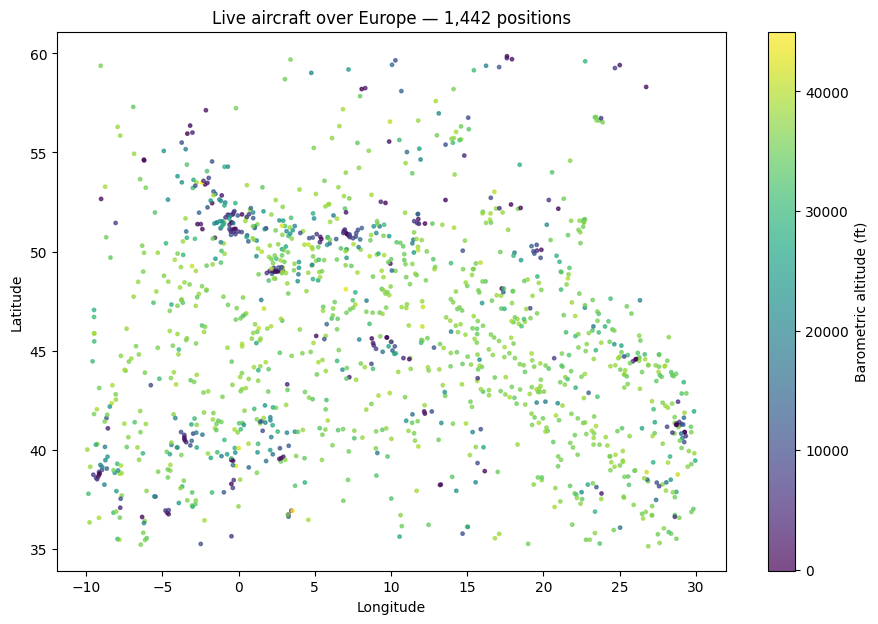

In [ ]:
import matplotlib.pyplot as plt

EUROPE = (35, -10, 60, 30)   # lamin, lomin, lamax, lomax
snap, raw = fetch_states(bbox=EUROPE)
eu = clean_states(raw)

plot_df = eu.dropna(subset=["longitude", "latitude"])

fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(
    plot_df["longitude"], plot_df["latitude"],
    c=plot_df["altitude_ft"], cmap="viridis", s=6, alpha=0.7
)
plt.colorbar(sc, label="Barometric altitude (ft)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title(f"Live aircraft over Europe — {len(plot_df):,} positions")
ax.set_aspect(1.3)   # rough lat/lon aspect correction
plt.show()

In [ ]:
df["origin_country"].value_counts().head(10)

origin_country
United States     7090
Canada             486
Australia          355
United Kingdom     341
Ireland            229
Malta              163
Turkey             160
Brazil             135
China              128
Germany            115
Name: count, dtype: int64

In [ ]:
# Pick a cruising jet from the current snapshot
snap, raw = fetch_states()
df = clean_states(raw)
candidate = (
    df[(~df.on_ground) & (df.altitude_ft > 30000) & (df.velocity > 200)]
      .dropna(subset=["latitude", "longitude"])
      .iloc[0]
)
target = candidate["icao24"]
print("Tracking", candidate["callsign"], f"({target})")

records, N = [], 10
for i in range(N):
    _, raw_i = fetch_states(icao24=[target])
    d = clean_states(raw_i)
    if not d.empty:
        records.append(d.iloc[0])
        print(f"{i+1:>2}/{N}  alt={d.iloc[0]['altitude_ft']:,.0f} ft  "
              f"spd={d.iloc[0]['speed_knots']:,.0f} kt")
    time.sleep(11)          # anonymous limit is ~10 s resolution
track = pd.DataFrame(records)

Tracking LPE2235 (e8027d)
 1/10  alt=37,300 ft  spd=431 kt
 2/10  alt=36,950 ft  spd=430 kt
 3/10  alt=36,550 ft  spd=430 kt
 4/10  alt=36,800 ft  spd=430 kt
 5/10  alt=35,725 ft  spd=428 kt
 6/10  alt=35,075 ft  spd=426 kt
 7/10  alt=34,900 ft  spd=430 kt
 8/10  alt=34,700 ft  spd=435 kt
 9/10  alt=34,725 ft  spd=434 kt
10/10  alt=34,275 ft  spd=441 kt


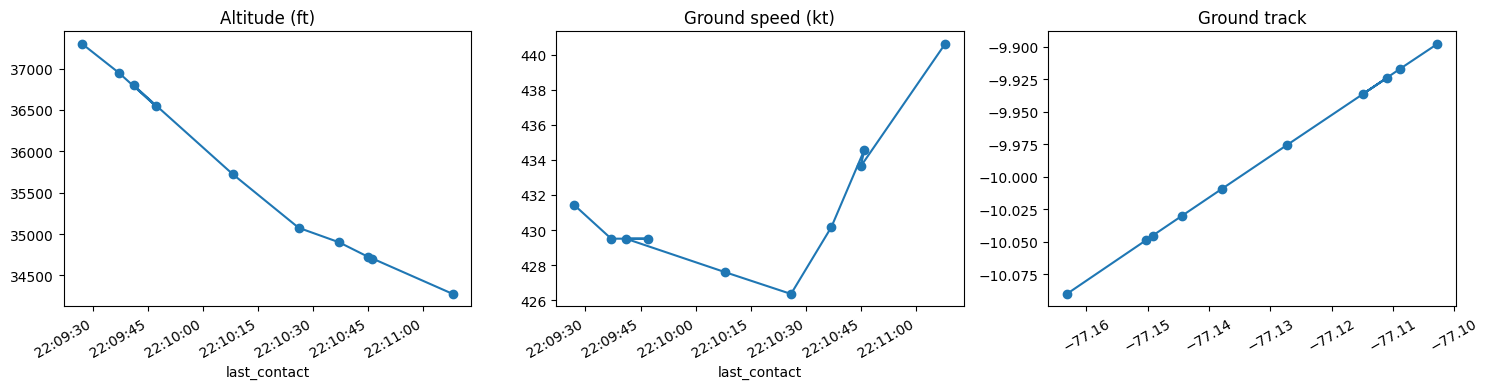

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
track.plot(x="last_contact", y="altitude_ft", ax=axes[0], marker="o", legend=False)
axes[0].set_title("Altitude (ft)")
track.plot(x="last_contact", y="speed_knots", ax=axes[1], marker="o", legend=False)
axes[1].set_title("Ground speed (kt)")
axes[2].plot(track["longitude"], track["latitude"], marker="o")
axes[2].set_title("Ground track")
for a in axes: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()